In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from cic_asymptotics.dgps import ExponentialDGP
from cic_asymptotics.estimators import compute_standard_error_estimated_ranks

In [2]:
# PARAMETERS
N = 10_000
B = 10_000
SEED = 12345
np.random.seed(SEED)

estimators = {
    "Smoothed Xavier": {"cdf_method": "smoothed", "se_method": "xavier"},
    "Smoothed Lewbel-Schennach": {"cdf_method": "smoothed", "se_method": "lewbel-schennach"},
    "Sample splitting": {"cdf_method": "smoothed", "se_method": "sample-splitting"},
}

# Exponential DGP

In [3]:
dgp = ExponentialDGP(n=N)


In [4]:
results = []
for b in tqdm(range(B)):
    y, z, x = dgp.generate()
    res = {}

    for k, args in estimators.items():
        theta_hat, standard_error = compute_standard_error_estimated_ranks(y=y, x=x, z=z, **args)
        res[k] = (theta_hat - dgp.theta0) / standard_error

    results.append(pd.Series(res))
    
results = (
    pd.concat(results, axis=1).T.replace({np.inf: np.nan}).dropna(axis=0, how="any")
)

  0%|          | 0/10000 [00:00<?, ?it/s]

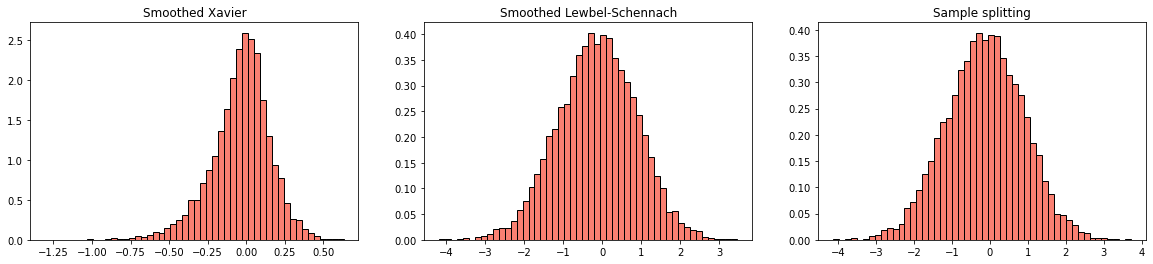

In [5]:
# Create subplots
fig, ax = plt.subplots(1, 3, figsize=(20, 4))

for i, (k, v) in enumerate(estimators.items()):
    ax_i = ax[i]    
    ax_i.hist(results[k], bins=50, color='salmon', edgecolor='black', density=True)
    ax_i.set_title(k)